# Lab 2: A Waste Sorter (CNNs, from Scratch and Pretrained)

**Hands-on lab · Convolutional neural networks on real photos**

Recycling only works if things go in the right bin. A greasy pizza box in the paper stream, a glass jar in the plastics or a battery in general waste can spoil a whole load, and sorting facilities spend a lot of effort pulling out what households got wrong. A phone app that looks at an item and says which bin it belongs in is a small, practical step: it helps people learn the rules, and the same idea, cameras over conveyor belts, is used in automated sorting plants.

In this lab we build that waste sorter with **convolutional neural networks (CNNs)**, the architecture designed for images. We do it two ways, and the comparison is the heart of the lab:
1. a small CNN **trained from scratch** on our photos;
2. a CNN **pretrained** on ImageNet, a very large collection of everyday photos (ResNet18), adapted to our bins, first as a frozen feature extractor, then fine-tuned.

Then we put the best model to a real-world test, on photos that look nothing like the training set. We watch it struggle, fix it with a little extra data, and wrap it in an app you can deploy.

**What you'll see in this lab:**
- a real photo dataset with six bins and an imbalanced class;
- a CNN built and trained from scratch, and why it struggles with a few thousand photos;
- transfer learning: frozen features, then fine-tuning the last block, with a caching trick that makes it fast on a CPU;
- per-class results, a confusion matrix and the model's actual mistakes;
- **distribution shift**: what happens on real-world photos, and how a small amount of matching data fixes much of it;
- a working app, ready to deploy to Hugging Face Spaces.

**The data.** *TrashNet*, by Gary Thung and Mindy Yang (MIT licence): 2,527 photos the authors took themselves of single items on a plain background, in six classes: cardboard, glass, metal, paper, plastic and trash (general waste). We use the resized version, from the dataset's page on the Hugging Face Hub. For the real-world test we also use photos of household waste collected from the web (a public recycling dataset on the Hub, `viola77data/recycling-dataset`). Those photos were gathered by a web image search, so their original owners hold the rights; we use them only to evaluate and adapt the model in class.

### How to use this notebook (running this lab)

- **Run the cells in order, from top to bottom.** Later cells use variables made by earlier ones (the photos, the data split, the trained models). If you restart the kernel, run everything again from the first cell.
- The **first run** trains everything and saves the models to `artifacts/`, which takes a few minutes on a laptop CPU. **Later runs load the saved models**, so the notebook runs through quickly in class. To retrain, delete `artifacts/` or set `TRAIN = True`.
- **The `TRAIN` flag** is set in the first code cell. It is `True` only when no saved model exists yet; the first cell prints it as `train now:`. When it is `False`, the training cells print `loaded artifacts/...` instead of an epoch-by-epoch log, and the prose below quotes the numbers from the training run.
- Data downloads into `data/` on the first run. The web photos take several minutes to download, so run the notebook once before class.
- **`LAUNCH_APP`** in the last cell opens the app inside the notebook; `python app.py` runs it on its own.
- Boxes marked **Try it yourself** are optional experiments. Some of them retrain a model and overwrite the files in `artifacts/`, so make a copy of that folder first if you want to keep the original models.

### Roadmap

1. **The Data**: load TrashNet, look at it, split it into training, validation and test sets.
2. **A CNN from Scratch**: build and train a small CNN on our photos only.
3. **A Pretrained CNN: Transfer Learning**: reuse ResNet18, first as frozen features, then fine-tuning its last block.
4. **How Good, and Where Does It Fail?**: per-bin recall, a confusion matrix and the actual mistakes.
5. **The Real-World Test**: try the models on web photos and meet distribution shift.
6. **Closing the Gap with a Little Real-World Data**: add web photos to training and fine-tune again.
7. **Is It Waste at All?**: teach the app to say "this doesn't look like waste" instead of forcing a bin.
8. **The Application**: the prediction function and the Gradio app.

At the end: **Key terms** (a short glossary) and **What We Learned**.

The first code cell imports the libraries, sets the `TRAIN` flag, fixes the random seeds (so you get the same split and the same results each run) and picks the device (a GPU if there is one, otherwise the CPU).

In [1]:
# Standard library: files, folders, timing and unzipping the dataset.
import os, glob, json, time, zipfile, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F                       # functions without weights: loss, resizing, pooling
import torchvision as tv                              # image transforms and pretrained models such as ResNet18
import matplotlib.pyplot as plt
from PIL import Image                                 # opens JPEG photos
from sklearn.model_selection import train_test_split  # stratified train/validation/test split
from sklearn.linear_model import LogisticRegression   # simple classifier on top of frozen features
from huggingface_hub import hf_hub_download, snapshot_download   # download the datasets from the Hugging Face Hub

# If the fine-tuned model is already saved, we skip training and just load the models (fast re-runs in class).
TRAIN = not os.path.exists("artifacts/waste_resnet18.pt")   # train the first time; afterwards load the saved models
# Fix the random seeds so the split, the shuffling and the starting weights are the same on every run.
torch.manual_seed(0)
np.random.seed(0)
# Use a GPU if there is one; everything in this lab also runs on a laptop CPU.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| torchvision", tv.__version__, "| device:", device, "| train now:", TRAIN)

PyTorch 2.14.1 | torchvision 0.29.1 | device: cpu | train now: False


/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The Data

The next cell downloads TrashNet on the first run, then builds two lists: the file path of every photo and its class number. The class number is simply the bin's position in the alphabetical list of bins (cardboard first, trash last).

In [2]:
# Download and unzip TrashNet only once; later runs find the folder and skip this block.
if not os.path.exists("data/dataset-resized"):
    zpath = hf_hub_download("garythung/trashnet", "dataset-resized.zip", repo_type="dataset", local_dir="data")
    with zipfile.ZipFile(zpath) as z:
        z.extractall("data")
    # Remove the macOS metadata folder that comes inside the zip, and the zip itself to save disk space.
    shutil.rmtree("data/__MACOSX", ignore_errors=True); os.remove(zpath)
# One sub-folder per bin. Sorting gives a fixed class order, so class number k always means the same bin.
CLASSES = sorted(os.listdir("data/dataset-resized"))
CLASSES = [c for c in CLASSES if os.path.isdir(f"data/dataset-resized/{c}")]   # keep folders only, skip stray files
# Build two parallel lists: the path of every photo and its class number (0 = cardboard, ..., 5 = trash).
files, labels = [], []
for k, c in enumerate(CLASSES):
    fs = sorted(glob.glob(f"data/dataset-resized/{c}/*.jpg"))   # sorted, so the order is the same on every computer
    files += fs; labels += [k] * len(fs)
labels = np.array(labels)                             # NumPy array, so we can count and select by class easily
# Report the number of photos, the size of one photo and how many photos each bin has (the class balance).
print(f"{len(files)} photos | size {Image.open(files[0]).size} | classes:", {c: int((labels == k).sum()) for k, c in enumerate(CLASSES)})

2527 photos | size (512, 384) | classes: {'cardboard': 403, 'glass': 501, 'metal': 410, 'paper': 594, 'plastic': 482, 'trash': 137}


There are 2527 photos, each 512 × 384 pixels. The classes are imbalanced: paper has 594 photos but trash only 137. Expect the model to find trash hardest, because it sees the fewest examples, and because "general waste" is a mixed bag of things with no single look.

Before modelling anything, it's worth looking at the data. Here is one photo from each bin:

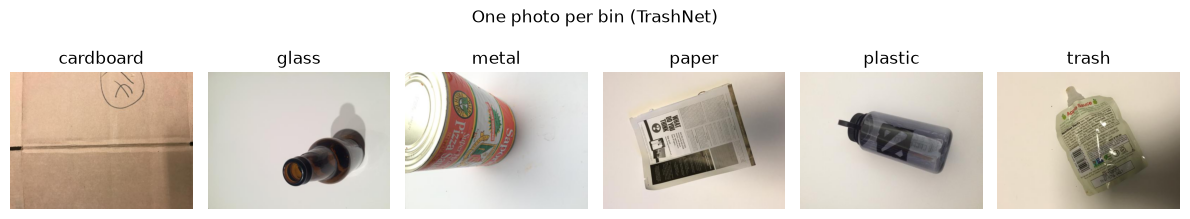

In [3]:
# Show one example photo per bin, to see what the data looks like before modelling it.
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for k, (ax, c) in enumerate(zip(axes, CLASSES)):
    ax.imshow(Image.open(files[int(np.where(labels == k)[0][0])])); ax.set_title(c); ax.axis("off")   # the first photo of each class
plt.suptitle("One photo per bin (TrashNet)"); plt.tight_layout(); plt.show()

Each photo shows a single item on a plain, light background, taken under similar lighting. That makes the task cleaner than real life, and it will matter in Sections 5 and 6.

We split the photos into training (70%), validation (15%) and test (15%), keeping the class proportions the same in each:

- The **training set** is what the models learn from.
- The **validation set** is used during training to make choices, such as which epoch to keep.
- The **test set** is used once, at the very end, to report an honest score on photos that played no part in any decision.

Keeping the proportions the same in each set is called a **stratified** split. It matters here because trash is rare: a purely random split could leave very few trash photos in the test set.

In [4]:
# Split photo numbers (not the photos themselves) into three groups:
#   training (70%)   - the models learn from these;
#   validation (15%) - used during training to pick the best epoch;
#   test (15%)       - used once at the end, for an honest score on photos the models never influenced.
# stratify keeps the class proportions the same in every group; random_state makes the split repeatable.
idx = np.arange(len(files))
tr_idx, rest = train_test_split(idx, test_size=0.3, stratify=labels, random_state=0)
va_idx, te_idx = train_test_split(rest, test_size=0.5, stratify=labels[rest], random_state=0)   # split the 30% in half
print(f"train {len(tr_idx)} | validation {len(va_idx)} | test {len(te_idx)} photos")

train 1768 | validation 379 | test 380 photos


To keep training fast, we resize every photo to 224 × 224 once and keep them all in memory as 8-bit integers:

In [6]:
# Resize every photo to 224 x 224 (the size ResNet18 was trained on) and turn it into a tensor of 0-255 integers.
to_224 = tv.transforms.Compose([tv.transforms.Resize((224, 224)), tv.transforms.PILToTensor()])
t0 = time.perf_counter()
# Decode all photos once and keep them in memory, so training never has to re-read JPEG files from disk.
# uint8 (one byte per value) uses a quarter of the memory of float32; we convert small batches to float when needed.
images = torch.stack([to_224(Image.open(f).convert("RGB")) for f in files])   # (N, 3, 224, 224), uint8 to save memory
print("image tensor:", tuple(images.shape), images.dtype, f"| {images.numel() / 1e6:.0f} MB | loaded in {time.perf_counter() - t0:.0f} s")
y = torch.tensor(labels)                              # labels as a PyTorch tensor, shape (N,), for the loss function

image tensor: (2527, 3, 224, 224) torch.uint8 | 380 MB | loaded in 3 s


In [11]:
images.shape

torch.Size([2527, 3, 224, 224])

**How to read this output.** The shape is (number of photos, colour channels, height, width): red, green and blue channels of 224 × 224 pixels each. The type `uint8` means one byte per value (0 to 255). Stored as 32-bit floats, the same tensor would take four times the memory, so we convert only small batches to floats when we need them.

## 2. A CNN from Scratch

A CNN slides small learned filters across the image (Note 5.2). Early layers respond to edges and colours, and later layers combine them into textures, shapes and parts. Our small CNN has four blocks, each doing convolution → batch normalisation → ReLU → max-pooling, which halves the image size and lets the next block see a wider area. Global average pooling then turns the final feature maps into one vector, and a linear layer maps it to the six bins. To save time we train it on 112 × 112 copies of the photos, and flip half of them left-to-right at random each epoch (**data augmentation**: a flipped bottle is still a bottle).

The building blocks, in plain words:
- **Convolution**: a small grid of weights (here 3 × 3 pixels) slides over the image and, at every position, computes a weighted sum of the pixels under it. The result is a **feature map**, which is large wherever the pattern the filter has learned appears. The same filter is reused at every position, so a pattern is recognised wherever it is in the photo.
- **Batch normalisation (BatchNorm)**: rescales each channel's values to a stable range, using the mean and spread of the current mini-batch during training and stored averages at prediction time. It makes training faster and steadier. This is why we switch models between `model.train()` and `model.eval()`.
- **Pooling**: shrinks a feature map by summarising small regions. **Max-pooling** keeps the largest value in each 2 × 2 square, halving the height and width. **Global average pooling** averages each whole feature map into a single number.

The next cell defines the network, a helper that prepares a batch of photos for it (with or without flips), and a helper that predicts bins for a set of photos.

In [ ]:
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self, n_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [24]:
class SmallCNN(nn.Module):
    """Four convolution blocks, then global average pooling and a linear classifier.

    Input: a batch of normalised photos, shape (B, 3, 112, 112).
    Output: one raw score (logit) per bin, shape (B, n_classes). Softmax would turn them into probabilities;
    the cross-entropy loss does that internally, so the model returns raw scores.
    Each block halves the height and width: 112 -> 56 -> 28 -> 14 -> 7, while the channels grow 3 -> 32 -> 64 -> 128 -> 128.
    """
    def __init__(self, n_classes=6):
        """Build the layers. n_classes is the number of bins (6 for TrashNet)."""
        super().__init__()
        def block(c_in, c_out):
            """One block: (B, c_in, H, W) -> (B, c_out, H/2, W/2).

            Conv2d with 3 x 3 filters (padding=1 keeps H and W), BatchNorm to keep the values in a stable range
            and speed up training, ReLU for non-linearity, then max-pooling to halve the size.
            """
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))
        # Four blocks: (B, 3, 112, 112) -> (B, 128, 7, 7). Later blocks see a wider area of the photo.
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 128))
        # Head: average each of the 128 feature maps to one number -> (B, 128), drop 30% of them at random
        # during training (Dropout, to reduce overfitting), then a linear layer gives one score per bin.
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))
    def forward(self, x):                               # x: (B, 3, 112, 112)
        """Run a batch through the network: (B, 3, 112, 112) -> scores (B, 6)."""
        return self.head(self.features(x))             # (B, 6)

def small_input(ix, augment=False):
    """Prepare the photos with numbers ix for the small CNN.

    ix: array of photo numbers, length B. Returns a float tensor (B, 3, 112, 112), roughly centred on 0.
    If augment is True, about half of the photos are flipped left-to-right (training only).
    """
    # Convert to floats in [0, 1] and shrink to 112 x 112: four times fewer pixels, so training is much faster.
    # antialias=True smooths before shrinking, which avoids jagged, noisy edges.
    x = F.interpolate(images[ix].float() / 255, size=112, mode="bilinear", antialias=True)   # (B, 3, 112, 112)
    if augment:
        # Data augmentation: a mirrored bottle is still a bottle, so flips give the model "new" photos for free.
        flip = torch.rand(len(ix)) < 0.5               # True for about half of the batch
        x[flip] = x[flip].flip(-1)                     # random left-right flips
    # Simple normalisation: [0, 1] becomes about [-2, 2], centred on 0, which helps training.
    return (x - 0.5) / 0.25

def accuracy_small(model, ix):
    """Predict a bin for each photo in ix with the small CNN.

    Returns a tensor of predicted class numbers, shape (len(ix),). Despite the name, it returns predictions;
    comparing them with the true labels gives the accuracy.
    """
    model.eval()                                       # evaluation mode: Dropout off, BatchNorm uses its stored statistics
    with torch.no_grad():                              # no gradients needed for prediction: faster and uses less memory
        # Predict in batches of 128 photos to limit memory use; argmax picks the bin with the highest score.
        return torch.cat([model(small_input(ix[i:i + 128]).to(device)).argmax(1).cpu() for i in range(0, len(ix), 128)])

scratch = SmallCNN().to(device)                       # a fresh network with random weights
# Count the learnable numbers (weights and biases) in the network.
print(f"parameters: {sum(p.numel() for p in scratch.parameters()):,}")

parameters: 242,310


The network has 242,310 parameters, all learned from our 1,768 training photos. We train for 12 epochs and keep the epoch with the best validation accuracy:

In [25]:
os.makedirs("artifacts", exist_ok=True)               # where the trained models are saved
if TRAIN:
    # AdamW: a standard optimiser. weight_decay gently pulls weights towards 0, a mild guard against overfitting.
    opt = torch.optim.AdamW(scratch.parameters(), lr=2e-3, weight_decay=1e-4)
    # g: a seeded random generator for shuffling, so runs are repeatable. best = (accuracy, weights, epoch).
    g = torch.Generator().manual_seed(0); best = (-1, None); t0 = time.perf_counter()
    for epoch in range(1, 13):                        # 12 epochs: 12 passes over the training photos
        scratch.train()                               # training mode: Dropout on, BatchNorm uses the batch's statistics
        # Shuffle the training photo numbers, then cut them into mini-batches of 32.
        for b in torch.tensor(tr_idx)[torch.randperm(len(tr_idx), generator=g)].split(32):
            opt.zero_grad()                           # clear the gradients left over from the previous batch
            # Forward pass on augmented photos, cross-entropy loss against the true bins, then backpropagation.
            F.cross_entropy(scratch(small_input(b, augment=True).to(device)), y[b].to(device)).backward()
            opt.step()                                # update the weights a little, against the gradient
        # After each epoch, measure accuracy on the validation photos (never trained on).
        acc = (accuracy_small(scratch, va_idx) == y[va_idx]).float().mean().item()
        if acc > best[0]:
            # Keep a copy of the weights from the best epoch so far. clone() makes a real copy, not a reference
            # that later training would overwrite. This guards against ending on a worse, noisier epoch.
            best = (acc, {k: v.clone() for k, v in scratch.state_dict().items()}, epoch)
        print(f"epoch {epoch:>2}: validation accuracy {acc:.3f}")
    # Go back to the best epoch's weights and save them, so later runs can skip training.
    scratch.load_state_dict(best[1]); torch.save(best[1], "artifacts/scratch_cnn.pt")
    print(f"kept epoch {best[2]} | training took {time.perf_counter() - t0:.0f} s")
else:
    # Later runs: load the weights saved by the first run instead of training again.
    scratch.load_state_dict(torch.load("artifacts/scratch_cnn.pt")); print("loaded artifacts/scratch_cnn.pt")
# The test photos are used here, once, after all choices were made on validation: an honest final score.
scratch_test = accuracy_small(scratch, te_idx)
print(f"small CNN from scratch: test accuracy {(scratch_test == y[te_idx]).float().mean():.3f}")

loaded artifacts/scratch_cnn.pt
small CNN from scratch: test accuracy 0.674


epoch  2: validation accuracy 0.501


epoch  3: validation accuracy 0.464


epoch  4: validation accuracy 0.573


epoch  5: validation accuracy 0.586


...

epoch  9: validation accuracy 0.641


epoch 10: validation accuracy 0.639


epoch 11: validation accuracy 0.670


epoch 12: validation accuracy 0.649
kept epoch 11 | training took 92 s


small CNN from scratch: test accuracy 0.674


Validation accuracy climbs slowly and unevenly, from 0.512 after the first epoch to 0.670 at epoch 11, the one we keep. On test, the from-scratch CNN reaches **0.674**. That's far better than guessing among six bins, but not good enough for an app: about one item in three would go in the wrong bin. The problem is data. A CNN learning from scratch has to discover everything (edges, textures, what makes glass look like glass) from fewer than two thousand photos.

**What to notice.** If you see `loaded artifacts/scratch_cnn.pt`, the model was loaded rather than trained, and there is no epoch log; the numbers above come from the training run. Keeping the best epoch on *validation* (not test) means the test score is still an honest, untouched estimate.

> **Try it yourself (optional): train the small CNN for longer.** In the training cell above, change `range(1, 13)` to `range(1, 25)` and temporarily change `if TRAIN:` to `if True:` so the cell trains even though a saved model exists (this overwrites `artifacts/scratch_cnn.pt`). *What to look for:* does validation accuracy keep rising, or level off and bounce around? Does the test accuracy get anywhere near the pretrained models below?

## 3. A Pretrained CNN: Transfer Learning

Instead of starting from scratch, we can start from a CNN that has already learned to see. **ResNet18** was trained on ImageNet, a very large collection of photos of everyday objects (the cell below prints its number of categories). Its early and middle layers have learned general visual features (edges, textures, shapes, materials) that are useful far beyond ImageNet's categories. Reusing them for a new task is called **transfer learning**.

ResNet18 is made of a stem and four blocks of layers (`layer1` to `layer4`), followed by a classifier. We'll keep everything up to `layer3` frozen. Since frozen layers always give the same output for the same photo, we can compute their output **once** for every photo and reuse it. That's a real engineering trick for training on a CPU: each epoch then only has to run the last block.

A **frozen** layer is one whose weights we do not change during training. The cell below also normalises the photos the way ImageNet models expect (subtracting ImageNet's average colour and dividing by its spread): a pretrained model only works well if its inputs are prepared like its training data.

In [26]:
# ResNet18 with weights learned on ImageNet, downloaded on first use (about 45 MB).
weights = tv.models.ResNet18_Weights.IMAGENET1K_V1
weights

ResNet18_Weights.IMAGENET1K_V1

In [27]:
# eval(): BatchNorm uses its stored ImageNet statistics. We never train this copy; it only computes features.
resnet = tv.models.resnet18(weights=weights).to(device).eval()      # pretrained on ImageNet
print(f"ResNet18: {sum(p.numel() for p in resnet.parameters()):,} parameters | ImageNet categories: {len(weights.meta['categories'])} | "
      f"ImageNet top-1 accuracy (from torchvision): {weights.meta['_metrics']['ImageNet-1K']['acc@1']}")

ResNet18: 11,689,512 parameters | ImageNet categories: 1000 | ImageNet top-1 accuracy (from torchvision): 69.758


In [28]:
# The per-channel (red, green, blue) mean and standard deviation of ImageNet photos.
# Pretrained models expect inputs normalised exactly like their training data; view() shapes them as (1, 3, 1, 1)
# so they broadcast over a batch (B, 3, 224, 224).
mean, std = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def resnet_input(ix):
    """Photos with numbers ix as ResNet input: uint8 (B, 3, 224, 224) -> normalised float (B, 3, 224, 224)."""
    return ((images[ix].float() / 255 - mean) / std)                # the normalisation ImageNet models expect

def up_to_layer3(x):                                                # the frozen part of the network
    """Run normalised photos through ResNet18 up to the end of layer3.

    x: (B, 3, 224, 224) -> activations (B, 256, 14, 14): 256 feature maps, each 14 x 14.
    These are the stem (conv1, bn1, relu, maxpool) and the first three blocks, which we keep frozen.
    """
    r = resnet
    # Stem: (B, 3, 224, 224) -> (B, 64, 56, 56); layer1 keeps that; layer2 -> (B, 128, 28, 28); layer3 -> (B, 256, 14, 14).
    return r.layer3(r.layer2(r.layer1(r.maxpool(r.relu(r.bn1(r.conv1(x)))))))

In [29]:
t0 = time.perf_counter()
# inference_mode: like no_grad, but even lighter. We only read the network here; nothing is trained.
with torch.inference_mode():
    # The caching trick: frozen layers give the same output for the same photo every time, so we compute
    # layer-3 activations ONCE for all photos and store them. Fine-tuning then only has to run layer4 each epoch.
    # .half() stores them in 16-bit floats, halving the memory; we convert back to 32-bit when we use them.
    l3 = torch.cat([up_to_layer3(resnet_input(np.arange(i, min(i + 64, len(files)))).to(device)).cpu().half()
                    for i in range(0, len(files), 64)])           # (N, 256, 14, 14), stored in 16 bits
    # Finish the pretrained network from the cache: layer4 -> (B, 512, 7, 7), average pooling -> (B, 512).
    # These 512 numbers per photo are the frozen features for the logistic regression in the next cell.
    pooled = torch.cat([resnet.avgpool(resnet.layer4(l3[i:i + 64].float().to(device))).flatten(1).cpu()
                        for i in range(0, len(files), 64)])        # (N, 512): ResNet's final features
print("cached layer-3 activations:", tuple(l3.shape), "| final features:", tuple(pooled.shape), f"| {time.perf_counter() - t0:.0f} s")

cached layer-3 activations: (2527, 256, 14, 14) | final features: (2527, 512) | 33 s


cached layer-3 activations: (2527, 256, 14, 14) | final features: (2527, 512) | 28 s


ResNet18 has 11,689,512 parameters and was trained to recognise 1000 ImageNet categories; torchvision reports its ImageNet top-1 accuracy as 69.758%. Computing and caching the frozen layers' outputs for all 2,527 photos takes under a minute.

**How to read this output.** `(2527, 256, 14, 14)` means: for every photo, 256 feature maps of 14 × 14 values, the output of `layer3`. `(2527, 512)` is ResNet's final summary of each photo, 512 numbers, which we use next.

### 3.1 Frozen features

The simplest transfer: run each photo through the whole pretrained network and take its final 512-number feature vector, then train a simple logistic regression on those features. Nothing in the network changes.

These 512 numbers are called **frozen features**: features computed by a pretrained network that is not trained further. Only the small classifier on top learns.

In [30]:
# Frozen features: the network stays unchanged; we only fit a logistic regression on the 512 features per photo.
# C=1.0 is the default amount of regularisation; max_iter is raised so the solver has time to converge.
probe = LogisticRegression(max_iter=3000, C=1.0).fit(pooled[tr_idx].numpy(), labels[tr_idx])
# score() returns accuracy. Validation and test photos were not used to fit the classifier.
print(f"frozen ResNet18 + logistic regression: validation {probe.score(pooled[va_idx].numpy(), labels[va_idx]):.3f} | "
      f"test {probe.score(pooled[te_idx].numpy(), labels[te_idx]):.3f}")

frozen ResNet18 + logistic regression: validation 0.815 | test 0.821


Without training a single convolutional weight, the frozen ResNet18 features reach **0.821** test accuracy, well above the 0.674 of the CNN we trained from scratch. Features learned from a huge photo collection beat features learned from our 1,768 training photos.

### 3.2 Fine-tuning the last block

ImageNet's final features are tuned to ImageNet's categories (dogs, cars, fruit), not to "glass vs plastic". So we let the network's **last block** (`layer4`) adapt, along with a new six-class head. The earlier layers stay frozen. A small learning rate for the pretrained block (1e-4) and a larger one for the new head (1e-3) keep the pretrained weights from being overwritten (Note 8.4 explains why). We also flip the cached feature maps left-to-right at random, a cheap stand-in for flipping the photos.

**Fine-tuning** means continuing to train some or all of a pretrained network's weights on the new task, usually gently, so it adapts without forgetting what it already knows. Here the model's input is the cached `layer3` output, not the photo, so each epoch only runs `layer4` and the head. At the end, the cell also assembles a complete photo-in model for the app and saves it to `artifacts/`.

In [31]:
class FineTuned(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer4 = tv.models.resnet18(weights=weights).layer4
        self.head = nn.Linear(512, len(CLASSES))

    def forward(self, x):
        x = self.layer4(x)
        x = F.adaptive_avg_pool2d(x, 1)
        x = torch.flatten(x, 1)
        return self.head(x)


def predict_ft(model, indices):
    model.eval()
    with torch.no_grad():
        return torch.cat([
            model(l3[indices[i:i+128]].float().to(device)).cpu()
            for i in range(0, len(indices), 128)
        ])


ft = FineTuned().to(device)

In [32]:
class FineTuned(nn.Module):
    """ResNet18's last block (layer4) and a new 6-class head, trained on cached layer-3 activations.

    Input: layer-3 activations, shape (B, 256, 14, 14), from up_to_layer3 (the frozen part).
    Output: one score per bin, shape (B, 6).
    layer4 starts from the ImageNet weights and is adjusted (fine-tuned); the head starts random.
    """
    def __init__(self):
        """Copy a fresh pretrained layer4 and create a new linear head with one output per bin."""
        super().__init__()
        self.layer4 = tv.models.resnet18(weights=weights).layer4   # pretrained last block: (B, 256, 14, 14) -> (B, 512, 7, 7)
        self.head = nn.Linear(512, len(CLASSES))                   # replaces ImageNet's 1000-way classifier
    def forward(self, a):                                # a: (B, 256, 14, 14) from layer 3
        """layer4 -> global average pooling to (B, 512) -> linear head -> scores (B, 6)."""
        return self.head(F.adaptive_avg_pool2d(self.layer4(a), 1).flatten(1))   # (B, 6)

def predict_ft(model, ix):
    """Scores of a FineTuned model for the photos with numbers ix.

    Reads their cached layer-3 activations, so no photo goes through the frozen layers again.
    Returns raw scores (logits), shape (len(ix), 6); use .argmax(1) for the predicted bins.
    """
    model.eval()                                         # evaluation mode: BatchNorm in layer4 uses its stored statistics
    with torch.no_grad():
        # Batches of 128; .float() converts the 16-bit cache back to 32-bit for the computation.
        return torch.cat([model(l3[ix[i:i + 128]].float().to(device)).cpu() for i in range(0, len(ix), 128)])

ft = FineTuned().to(device)

In [33]:
if TRAIN:
    torch.manual_seed(0)                                 # repeatable random flips
    # Two learning rates: small (1e-4) for the pretrained layer4, so its useful ImageNet features are only nudged,
    # and larger (1e-3) for the new head, which starts from random and has more to learn.
    opt = torch.optim.AdamW([{"params": ft.layer4.parameters(), "lr": 1e-4}, {"params": ft.head.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    g = torch.Generator().manual_seed(0); best = (-1, None); t0 = time.perf_counter()
    for epoch in range(1, 6):                            # 5 epochs are enough when starting from pretrained weights
        ft.train()                                       # training mode: BatchNorm in layer4 updates from each batch
        for b in torch.tensor(tr_idx)[torch.randperm(len(tr_idx), generator=g)].split(32):   # shuffled batches of 32
            a = l3[b].float()                            # cached activations (B, 256, 14, 14), back to 32-bit
            flip = torch.rand(len(b)) < 0.5              # pick about half of the batch
            # Flipping the 14 x 14 maps left-to-right roughly matches what flipping the photo would give, without
            # re-running the frozen layers. That keeps augmentation while keeping the cache.
            a[flip] = a[flip].flip(-1)                   # flip the feature maps: a cheap stand-in for flipping photos
            # The usual step: clear gradients, forward + loss, backpropagate (only into layer4 and the head), update.
            opt.zero_grad(); F.cross_entropy(ft(a.to(device)), y[b].to(device)).backward(); opt.step()
        acc = (predict_ft(ft, va_idx).argmax(1) == y[va_idx]).float().mean().item()   # validation accuracy
        if acc > best[0]:
            best = (acc, {k: v.clone() for k, v in ft.state_dict().items()}, epoch)   # keep the best epoch's weights
        print(f"epoch {epoch}: validation accuracy {acc:.3f}")
    ft.load_state_dict(best[1])                          # return to the best epoch
    print(f"kept epoch {best[2]} | training took {time.perf_counter() - t0:.0f} s")
    # The app needs one ordinary model that takes photos, not cached activations. So we take a full pretrained
    # ResNet18 (its frozen part is identical) and put in our fine-tuned layer4 and our 6-class head as fc.
    full = tv.models.resnet18(weights=weights)                      # assemble a complete model for the app
    full.layer4.load_state_dict(ft.layer4.state_dict()); full.fc = nn.Linear(512, len(CLASSES)); full.fc.load_state_dict(ft.head.state_dict())
    torch.save(full.state_dict(), "artifacts/waste_resnet18.pt")
    json.dump({"classes": CLASSES}, open("artifacts/classes.json", "w"))   # the bin names, in order, for the app
else:
    # Later runs: rebuild the same architecture, load the saved weights, then copy layer4 and the head
    # back into the FineTuned model so it works on the cached activations as before.
    full = tv.models.resnet18(); full.fc = nn.Linear(512, len(CLASSES))
    full.load_state_dict(torch.load("artifacts/waste_resnet18.pt"))
    ft.layer4.load_state_dict(full.layer4.state_dict()); ft.head.load_state_dict(full.fc.state_dict())
    print("loaded artifacts/waste_resnet18.pt")
ft_test = predict_ft(ft, te_idx).argmax(1)               # predicted bins for the test photos, used once
print(f"fine-tuned ResNet18: test accuracy {(ft_test == y[te_idx]).float().mean():.3f}")

loaded artifacts/waste_resnet18.pt
fine-tuned ResNet18: test accuracy 0.905


epoch 2: validation accuracy 0.852


epoch 3: validation accuracy 0.871


epoch 4: validation accuracy 0.868


epoch 5: validation accuracy 0.881
kept epoch 5 | training took 60 s


fine-tuned ResNet18: test accuracy 0.905


Fine-tuning reaches 0.881 validation accuracy by epoch 5, and **0.905** on test. Adapting just the last block to our bins took about a minute.

> **Common mistake:** training a CNN from scratch on a small dataset because it feels more "real". With a few thousand images, starting from a pretrained network is almost always better, faster and cheaper. Train from scratch when you have very large amounts of data, or images so unusual that ImageNet features don't help.

> **Try it yourself (optional): unfreeze less, or adapt more boldly.** Copy `artifacts/` somewhere safe first: this retrains and overwrites `artifacts/waste_resnet18.pt`. In the fine-tuning cell, change `if TRAIN:` to `if True:` and try a different learning rate for `layer4`: `0` (only the head learns, close to frozen features) or `1e-3` (the same as the head). *What to look for:* how the validation accuracy changes from epoch to epoch, and whether the test accuracy lands nearer the frozen-features result or above the fine-tuned one. Then try removing the random flips (comment out the line `a[flip] = a[flip].flip(-1)`) and see whether validation accuracy is lower or less steady.

## 4. How Good, and Where Does It Fail?

Overall accuracy hides which bins work and which don't. Here is the recall for each bin (the share of that bin's test photos sorted correctly), for all three models:

In [34]:
# Test-set predictions of all three models, as tensors of class numbers, shape (380,).
results = {"small CNN from scratch": scratch_test, "frozen ResNet18 + logistic regression": torch.tensor(probe.predict(pooled[te_idx].numpy())),
           "fine-tuned ResNet18": ft_test}
yt = y[te_idx]                                           # the true bins of the test photos
# Table header: model name, overall test accuracy, then one column per bin (names cut to 9 letters).
print(f"{'model':<38} {'test acc':>8}   " + "  ".join(f"{c[:9]:>9}" for c in CLASSES))
for name, p in results.items():
    # Recall for bin k: of the test photos that truly belong to k, the share the model also put in k.
    rec = [((p == k) & (yt == k)).sum().item() / (yt == k).sum().item() for k in range(len(CLASSES))]
    print(f"{name:<38} {(p == yt).float().mean():>8.3f}   " + "  ".join(f"{r:>9.2f}" for r in rec))
# The number of test photos per bin: a recall based on few photos (such as trash) is less certain.
print(f"{'test photos per class':<38} {'':>8}   " + "  ".join(f"{(yt == k).sum().item():>9}" for k in range(len(CLASSES))))

model                                  test acc   cardboard      glass      metal      paper    plastic      trash
small CNN from scratch                    0.674        0.82       0.64       0.76       0.76       0.55       0.15
frozen ResNet18 + logistic regression     0.821        0.88       0.82       0.85       0.91       0.74       0.45
fine-tuned ResNet18                       0.905        0.95       0.84       0.94       0.99       0.86       0.70
test photos per class                                    60         76         62         89         73         20


**How to read this table.** Each row is a model; `test acc` is its overall accuracy; each bin column is that bin's recall. The last row shows how many test photos each bin has: a recall based on few photos can swing a lot when just one or two photos change.

Every bin improves from scratch → frozen → fine-tuned. **Trash** stays the hardest: 0.15 from scratch, 0.45 frozen, 0.70 fine-tuned, with only 20 test photos. Paper is easiest (0.99 fine-tuned).

A **confusion matrix** is a table of counts: each row is the true bin and each column is the bin the model predicted. The diagonal (top-left to bottom-right) holds the correct answers; every number off the diagonal is a mistake, and its position tells you what was confused with what. The confusion matrix shows *which* bins get mixed up:

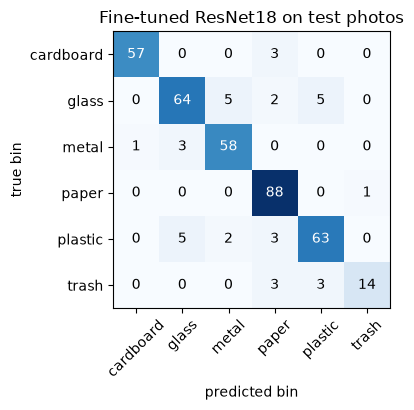

In [35]:
# Confusion matrix: row = true bin, column = predicted bin; each cell counts test photos.
# The diagonal holds the correct answers; everything off the diagonal is a mistake.
cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
for t_, p_ in zip(yt.tolist(), ft_test.tolist()):
    cm[t_, p_] += 1
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(cm, cmap="Blues")                              # darker blue = more photos
# Write each count in its cell; white text on dark cells, black on light ones, so it stays readable.
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45); ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
ax.set_xlabel("predicted bin"); ax.set_ylabel("true bin"); ax.set_title("Fine-tuned ResNet18 on test photos"); plt.tight_layout(); plt.show()

**How to read this plot.** Darker cells hold more photos. Read along a row to see where one true bin's photos ended up; read down a column to see what the model *calls* a given bin. The row totals are the test photos per bin from the table above.

The main mistakes are between **glass and plastic** (5 glass photos called plastic, 5 plastic photos called glass) and between glass and metal. Clear bottles and jars look alike in a photo. The mistakes themselves, the first eight in test order, are mostly understandable:

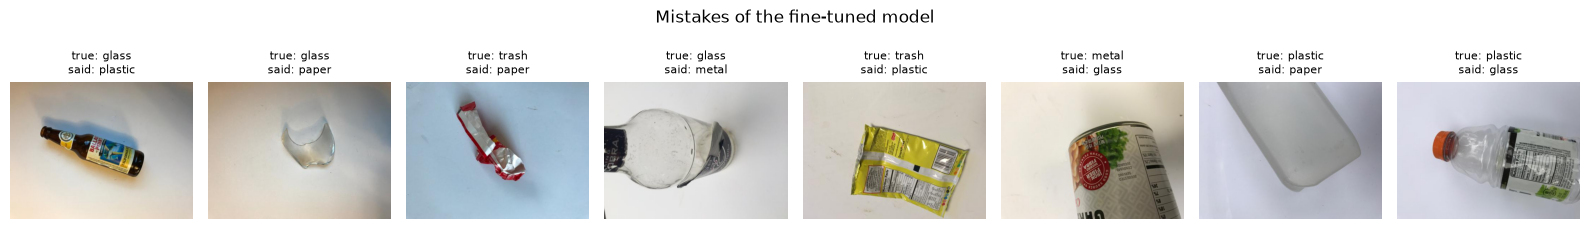

In [36]:
# Look at actual mistakes: positions in the test set where the prediction differs from the truth.
wrong = np.where(ft_test.numpy() != yt.numpy())[0][:8]                 # the first eight mistakes, in test order
fig, axes = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.6))
for ax, w in zip(np.atleast_1d(axes), wrong):            # atleast_1d: still works if there were only one mistake
    ax.imshow(Image.open(files[te_idx[w]])); ax.axis("off")   # te_idx maps the test position back to the photo file
    ax.set_title(f"true: {CLASSES[yt[w]]}\nsaid: {CLASSES[ft_test[w]]}", fontsize=8)
plt.suptitle("Mistakes of the fine-tuned model"); plt.tight_layout(); plt.show()

A transparent glass called paper, a crumpled snack wrapper (trash) called paper or plastic, a metal tin seen from an odd angle called glass. Some of these would fool a person in a quick glance too. Errors like these suggest what extra photos to collect.

> **Try it yourself (optional): the scratch model's confusion matrix.** In the confusion-matrix cell, replace `ft_test` with `scratch_test` (in the `zip(...)` line) and re-run it; no training needed. *What to look for:* which bins does the small CNN confuse that the fine-tuned model mostly gets right? Where do the trash photos go? Change it back afterwards.

## 5. The Real-World Test

So far the test photos came from the same source as the training photos: single items on plain backgrounds, under the same lighting. Real users will photograph items on kitchen counters, in their hands, in different light. This mismatch between training data and real-world data is called **distribution shift**, and it's one of the most common reasons models disappoint after deployment.

Let's test on web photos of household waste, which look very different. We take 40 photos (the first 40 by file name) for each of five bins that match ours. The web dataset has no general-waste folder, so trash is not tested here, and its folder names differ from ours (for example "aluminium" becomes our metal bin); the cell maps them to our bins:

In [37]:
# The web dataset's folder names, mapped to our bins. It has no "trash" folder, so we test five bins.
web_map = {"aluminium": "metal", "cardboard": "cardboard", "glass": "glass", "paper": "paper", "hard plastic": "plastic"}
# Download only the five folders we need (not the whole dataset). Files already downloaded are not fetched again.
web_dir = snapshot_download("viola77data/recycling-dataset", repo_type="dataset", local_dir="data/web",
                            allow_patterns=[f"{k}/*" for k in web_map])
web_files, web_labels = [], []
for folder, c in web_map.items():
    fs = sorted(glob.glob(f"data/web/{folder}/*.jpg"))[:40]            # the first 40 photos of each, by file name
    web_files += fs; web_labels += [CLASSES.index(c)] * len(fs)      # label with OUR class number for that bin
# Same preparation as TrashNet: 224 x 224, uint8. web: (200, 3, 224, 224); wy: the true bins, shape (200,).
web = torch.stack([to_224(Image.open(f).convert("RGB")) for f in web_files]); wy = torch.tensor(web_labels)
print(f"{len(web_files)} web photos:", {c: web_labels.count(CLASSES.index(c)) for c in web_map.values()})

Fetching 1372 files: 100%|███████████████| 1372/1372 [00:00<00:00, 1849.44it/s]


200 web photos: {'metal': 40, 'cardboard': 40, 'glass': 40, 'paper': 40, 'plastic': 40}


Fetching 1372 files:  28%|██▊       | 384/1372 [00:00<00:00, 1940.75it/s]

Fetching 1372 files:  44%|████▍     | 603/1372 [00:00<00:00, 2052.28it/s]

Fetching 1372 files:  60%|█████▉    | 819/1372 [00:00<00:00, 2092.46it/s]

Fetching 1372 files:  76%|███████▌  | 1038/1372 [00:00<00:00, 2125.23it/s]

Fetching 1372 files:  91%|█████████ | 1251/1372 [00:00<00:00, 2091.38it/s]

Fetching 1372 files: 100%|██████████| 1372/1372 [00:00<00:00, 2074.69it/s]

200 web photos: {'metal': 40, 'cardboard': 40, 'glass': 40, 'paper': 40, 'plastic': 40}


One web photo per bin, for comparison with the TrashNet photos in Section 1:

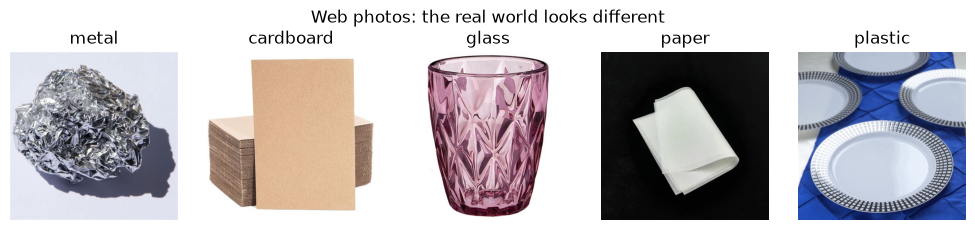

In [38]:
# One web photo per bin, to compare with the TrashNet photos shown in Section 1.
fig, axes = plt.subplots(1, 5, figsize=(10, 2.3))
for ax, (folder, c) in zip(axes, web_map.items()):
    ax.imshow(Image.open(sorted(glob.glob(f"data/web/{folder}/*.jpg"))[0]).convert("RGB")); ax.set_title(c); ax.axis("off")
plt.suptitle("Web photos: the real world looks different"); plt.tight_layout(); plt.show()

Different backgrounds, angles, lighting and even kinds of object: crumpled foil, stacked cardboard sheets, a decorative glass, paper plates. Here is how our models do:

In [39]:
# Run both trained models on the web photos. Nothing is trained here.
with torch.no_grad():
    # Small CNN: the same preparation as small_input (112 x 112, same normalisation), without flips.
    xs = F.interpolate(web.float() / 255, size=112, mode="bilinear", antialias=True)
    scratch.eval(); web_scratch = scratch(((xs - 0.5) / 0.25).to(device)).argmax(1).cpu()
    # Fine-tuned ResNet18: ImageNet normalisation, frozen layers up to layer3 (batches of 64), then the FineTuned part.
    a3 = torch.cat([up_to_layer3(((web[i:i + 64].float() / 255 - mean) / std).to(device)).cpu() for i in range(0, len(web), 64)])
    ft.eval(); web_ft = ft(a3.to(device)).argmax(1).cpu()
# Compare each model's accuracy on web photos with its accuracy on TrashNet's own test photos.
for name, p in (("small CNN from scratch", web_scratch), ("fine-tuned ResNet18", web_ft)):
    print(f"{name:<24} accuracy on web photos {(p == wy).float().mean():.3f} (on TrashNet test photos {(results[name] == yt).float().mean():.3f})")

small CNN from scratch   accuracy on web photos 0.330 (on TrashNet test photos 0.674)
fine-tuned ResNet18      accuracy on web photos 0.395 (on TrashNet test photos 0.905)


The fine-tuned model drops from 0.905 on TrashNet's test photos to **0.395** on web photos, and the from-scratch CNN to 0.330. The models had learned TrashNet's world, plain backgrounds included, more than they had learned what makes glass glass. A test score from the same source as the training data can badly overestimate real-world performance.

**What to notice.** The fine-tuned model is still the better of the two, but the gap between them shrinks a lot. A higher score on the familiar test set did not carry over to the new photos in the same proportion.

## 6. Closing the Gap with a Little Real-World Data

The most effective fix for distribution shift is usually the simplest: **add training data that looks like the real world**. We take the *next* 40 web photos of each bin (never used for testing), 200 in total, add them to the 1,768 TrashNet training photos, and fine-tune again exactly as before.

The first cell loads the extra photos and caches their `layer3` outputs, like the TrashNet photos:

In [40]:
# Extra training photos from the web, taken from positions 40-79 of each folder, so they never overlap the
# 200 test photos (positions 0-39). Testing on photos we trained on would give a falsely good score.
mix_files, mix_labels = [], []
for folder, c in web_map.items():
    fs = sorted(glob.glob(f"data/web/{folder}/*.jpg"))[40:80]           # the NEXT 40 per class: never used for testing
    mix_files += fs; mix_labels += [CLASSES.index(c)] * len(fs)
mix = torch.stack([to_224(Image.open(f).convert("RGB")) for f in mix_files])   # (200, 3, 224, 224), uint8
with torch.inference_mode():
    # Cache their layer-3 activations too, in 16 bits, exactly like the TrashNet cache.
    mix_l3 = torch.cat([up_to_layer3(((mix[i:i + 64].float() / 255 - mean) / std).to(device)).cpu().half() for i in range(0, len(mix), 64)])
# The new training set: TrashNet training activations followed by the web ones, with matching labels.
l3_mixed = torch.cat([l3[tr_idx], mix_l3]); y_mixed = torch.cat([y[tr_idx], torch.tensor(mix_labels)])
print(f"training set: {len(tr_idx)} TrashNet photos + {len(mix_files)} web photos")

training set: 1768 TrashNet photos + 200 web photos


The second cell fine-tunes a fresh copy of the model on the mixed training set, with the same settings as Section 3.2. The best epoch is still chosen on TrashNet's validation photos, so the 200 web *test* photos play no part in training or in any choice. It then compares the two fine-tuned models side by side:

In [41]:
# A fresh FineTuned model (pretrained layer4, new head), trained exactly as before but on the mixed set.
ft_mix = FineTuned().to(device)
if TRAIN or not os.path.exists("artifacts/waste_resnet18_mixed.pt"):
    torch.manual_seed(0)
    # Same optimiser and the same two learning rates as the first fine-tuning, so only the data differs.
    opt = torch.optim.AdamW([{"params": ft_mix.layer4.parameters(), "lr": 1e-4}, {"params": ft_mix.head.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    g = torch.Generator().manual_seed(0); best = (-1, None); t0 = time.perf_counter()
    for epoch in range(1, 6):
        ft_mix.train()
        # Shuffle positions in the mixed set (not photo numbers), so TrashNet and web photos share the batches.
        for b in torch.randperm(len(y_mixed), generator=g).split(32):
            a = l3_mixed[b].float()
            flip = torch.rand(len(b)) < 0.5
            a[flip] = a[flip].flip(-1)                   # the same cheap flip augmentation as before
            opt.zero_grad(); F.cross_entropy(ft_mix(a.to(device)), y_mixed[b].to(device)).backward(); opt.step()
        # The web test photos play no part in choosing the epoch, so the web score below stays honest.
        acc = (predict_ft(ft_mix, va_idx).argmax(1) == y[va_idx]).float().mean().item()   # chosen on TrashNet validation, as before
        if acc > best[0]:
            best = (acc, {k: v.clone() for k, v in ft_mix.state_dict().items()}, epoch)
    ft_mix.load_state_dict(best[1])
    print(f"kept epoch {best[2]} | training took {time.perf_counter() - t0:.0f} s")
    # Assemble and save a complete photo-in model, as before. This is the model the app loads.
    full_mix = tv.models.resnet18(weights=weights)
    full_mix.layer4.load_state_dict(ft_mix.layer4.state_dict()); full_mix.fc = nn.Linear(512, len(CLASSES)); full_mix.fc.load_state_dict(ft_mix.head.state_dict())
    torch.save(full_mix.state_dict(), "artifacts/waste_resnet18_mixed.pt")
else:
    # Later runs: load the saved mixed model and copy its layer4 and head into ft_mix.
    full_mix = tv.models.resnet18(); full_mix.fc = nn.Linear(512, len(CLASSES))
    full_mix.load_state_dict(torch.load("artifacts/waste_resnet18_mixed.pt"))
    ft_mix.layer4.load_state_dict(full_mix.layer4.state_dict()); ft_mix.head.load_state_dict(full_mix.fc.state_dict())
    print("loaded artifacts/waste_resnet18_mixed.pt")
ft_mix.eval()                                           # evaluation mode: BatchNorm uses its stored statistics
with torch.no_grad():
    web_mix = ft_mix(a3.to(device)).argmax(1).cpu()     # the same 200 web test photos as in Section 5
mix_test = predict_ft(ft_mix, te_idx).argmax(1)         # and the same TrashNet test photos
# Before and after, side by side: did the web score improve, and did the TrashNet score suffer?
print(f"fine-tuned on TrashNet only:      web photos {(web_ft == wy).float().mean():.3f} | TrashNet test {(ft_test == yt).float().mean():.3f}")
print(f"fine-tuned with 200 web photos:   web photos {(web_mix == wy).float().mean():.3f} | TrashNet test {(mix_test == yt).float().mean():.3f}")

loaded artifacts/waste_resnet18_mixed.pt
fine-tuned on TrashNet only:      web photos 0.395 | TrashNet test 0.905
fine-tuned with 200 web photos:   web photos 0.735 | TrashNet test 0.911


fine-tuned on TrashNet only:      web photos 0.395 | TrashNet test 0.905
fine-tuned with 200 web photos:   web photos 0.735 | TrashNet test 0.911


With just 200 extra photos, accuracy on the unseen web photos jumps from 0.395 to **0.735**, while accuracy on TrashNet's test photos stays the same (0.905 before, 0.911 after). A modest amount of data that matches where the model will be used did more than any change of architecture could.

For a real deployment the lesson is concrete: before launch, photograph items the way users will, in kitchens and under different lights, and add them to training. Then keep collecting the photos the app gets wrong.

> **Try it yourself (optional): how few web photos are enough?** In the first cell of this section, change `[40:80]` to `[40:50]` (10 per bin, 50 in total). Then rename or delete `artifacts/waste_resnet18_mixed.pt` so the next cell retrains (the app uses this file, so keep a copy). *What to look for:* how much of the jump in web accuracy survives with a quarter of the extra photos, and whether the TrashNet test accuracy changes.

## 7. Is It Waste at All?

Our model has exactly six outputs, and **softmax** always shares 100% among them. So whatever photo it sees (a face, a cat, a living room) it *must* name a bin. Nothing in its training ever showed it something that wasn't waste, so it has no way to say "none of these".

This is a general problem called **out-of-distribution (OOD) input**: an input unlike anything in the training data. A deployed app meets such inputs all the time, so it needs a way to notice them.

To test this honestly we need photos that are *not* waste. We take them from **COCO**, a large public collection of everyday photos (people, rooms, animals, streets). We keep only photos under open licences, and we drop any photo whose captions mention something waste-like. We download two separate sets:
- 1,000 photos from COCO's *training* split, to train a check;
- 400 from its *validation* split, split in half: one half to choose the check (validation), the other to test it once.

The next cell downloads them the first time (a few minutes); later runs find them on disk.

In [43]:
# --- Non-waste photos: everyday COCO photos (people, rooms, animals, streets) -------------------------------
# COCO (cocodataset.org) is a large public collection of everyday photos, each with five human-written captions.
# We keep only photos under open licences, and drop any photo whose captions mention a waste-like word
# (bottle, can, box, paper, glass, ...), so "not waste" really means not waste.
import re, socket, urllib.request, concurrent.futures as cf
import pandas as pd

COCO_LICENCES = {4: "CC BY 2.0", 5: "CC BY-SA 2.0", 7: "No known copyright restrictions", 8: "United States Government Work"}
WASTE_WORDS = re.compile(r"\b(bottles?|cans?|trash|garbage|rubbish|litter|waste|recycl\w*|cardboard|boxe?s?|cartons?|papers?|"
                         r"newspapers?|plastic|glass(es)?|cups?|jars?|bags?|bins?|tins?|containers?|wrappers?|dumpster|mugs?|"
                         r"soda|beer|wine)\b", re.I)

def download_coco(parquet_file, n, out_dir):
    """Download `n` open-licence COCO photos without waste-like captions into `out_dir`; return their file paths.

    parquet_file: the COCO index (file name, image URL, licence, captions) from the `phiyodr/coco2017` dataset.
    The choice is random but fixed (random_state=0), and photos already on disk are not downloaded again.
    """
    if len(glob.glob(f"{out_dir}/*.jpg")) >= n:                          # already downloaded: nothing to do
        return sorted(glob.glob(f"{out_dir}/*.jpg"))
    os.makedirs(out_dir, exist_ok=True); socket.setdefaulttimeout(30)
    index = pd.read_parquet(hf_hub_download("phiyodr/coco2017", parquet_file, repo_type="dataset"))
    ok = index[index.license.isin(COCO_LICENCES) & ~index.captions.apply(lambda cs: any(WASTE_WORDS.search(c) for c in cs))]
    pick = ok.sample(n, random_state=0)
    def get(row):                                                        # one photo; skip it if it's already there
        path = f"{out_dir}/{os.path.basename(row.file_name)}"
        if not os.path.exists(path):
            urllib.request.urlretrieve(row.coco_url, path)
        return path
    with cf.ThreadPoolExecutor(16) as ex:                                # 16 downloads at a time
        list(ex.map(get, [r for _, r in pick.iterrows()]))
    json.dump([{"file": os.path.basename(r.file_name), "licence": COCO_LICENCES[r.license], "flickr_url": r.flickr_url,
                "caption": r.captions[0]} for _, r in pick.iterrows()], open(f"{out_dir}/sources.json", "w"), indent=1)
    return sorted(glob.glob(f"{out_dir}/*.jpg"))

coco_train = download_coco("data/train-00000-of-00001-0084e041f1902997.parquet", 1000, "data/not_waste_train")  # to train the check
coco_eval = download_coco("data/validation-00000-of-00001-e3c37e369512a3aa.parquet", 400, "data/not_waste")     # to choose and test it
perm = np.random.default_rng(0).permutation(len(coco_eval))
coco_val, coco_test = [coco_eval[i] for i in perm[:200]], [coco_eval[i] for i in perm[200:]]   # two halves: choose, then test once
captions = {m["file"]: m["caption"] for m in json.load(open("data/not_waste/sources.json"))}
print(f"non-waste photos: {len(coco_train)} for training | {len(coco_val)} for validation | {len(coco_test)} for the test")

non-waste photos: 1000 for training | 200 for validation | 200 for the test


First, how does the current model treat these photos? The next cell asks it to sort the 200 non-waste test photos, and shows the six it is most sure about.

non-waste test photos put in a bin with at least 60% confidence: 0.595 | at least 90%: 0.145
bins they land in: {'cardboard': 42, 'glass': 58, 'metal': 23, 'paper': 26, 'plastic': 51, 'trash': 0}


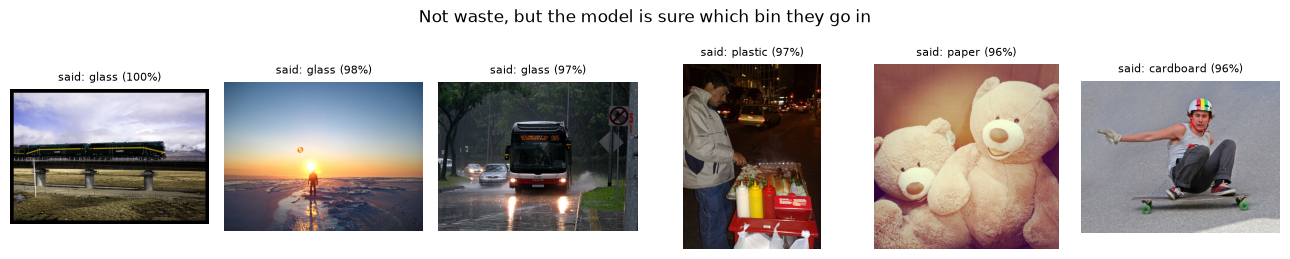

In [44]:
# --- What does our waste model say about photos that aren't waste? -----------------------------------------
def load_224(paths):
    """Load photos as a uint8 tensor (N, 3, 224, 224), squashed to 224 x 224 exactly as for the waste photos."""
    return torch.stack([to_224(Image.open(p).convert("RGB")) for p in paths])

coco_test_imgs = load_224(coco_test)
full_mix.eval()                                                          # evaluation mode: BatchNorm uses stored statistics
with torch.no_grad():
    p_coco = torch.cat([full_mix(((coco_test_imgs[i:i + 64].float() / 255 - mean) / std).to(device)).softmax(1).cpu()
                        for i in range(0, len(coco_test_imgs), 64)])     # (200, 6): bin probabilities for each photo
conf = p_coco.max(1).values                                              # how sure the model is of its top bin
print(f"non-waste test photos put in a bin with at least 60% confidence: {(conf >= 0.6).float().mean():.3f} | "
      f"at least 90%: {(conf >= 0.9).float().mean():.3f}")
print("bins they land in:", {c: int((p_coco.argmax(1) == k).sum()) for k, c in enumerate(CLASSES)})

fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for ax, i in zip(axes, conf.argsort(descending=True)[:6].tolist()):      # the six it is most sure about
    ax.imshow(Image.open(coco_test[i])); ax.axis("off")
    ax.set_title(f"said: {CLASSES[p_coco[i].argmax()]} ({conf[i]:.0%})", fontsize=8)
plt.suptitle("Not waste, but the model is sure which bin they go in"); plt.tight_layout(); plt.show()

**What to notice.**
- 59.5% of these non-waste photos get a bin with at least 60% confidence, which is the threshold our app uses for "Not sure". 14.5% get at least 90%.
- They land mostly in glass (58) and plastic (51).
- A train, a sunset, a bus and a pair of teddy bears are all "recyclable" with 96–100% confidence.

**A high softmax probability is not the same as "this looks like what I was trained on".** (The hot-dog stand does contain plastic bottles: our caption filter isn't perfect.)

### Describing photos in general terms

To judge "is this waste at all?", we need features that still describe photos *in general*. Our fine-tuned layer 4 has been retrained to think only in bins. But the original ImageNet ResNet18 (`resnet` in this notebook) still has its own layer 4, which learned to describe 1,000 kinds of everyday things. Layers 1–3 are the same in both networks, so the cached layer-3 activations can be reused.

Each photo becomes a 512-number **feature vector**, scaled to length 1, so that comparing two photos is just a dot product (their **cosine similarity**).

In [45]:
# --- General-purpose features for the check ----------------------------------------------------------------
# Our fine-tuned layer 4 now only "thinks in bins". The ORIGINAL ImageNet layer 4 (in `resnet`) still describes
# photos in general terms (faces, fur, furniture, sky, ...), and layers 1-3 are shared. So we describe every photo
# with ImageNet's layer-4 features, scaled to length 1 so that only their direction matters.
def general_features(act3):
    """ImageNet layer-4 features from layer-3 activations (N, 256, 14, 14) -> (N, 512), each row of length 1."""
    with torch.inference_mode():
        f = torch.cat([resnet.avgpool(resnet.layer4(act3[i:i + 64].float().to(device))).flatten(1).cpu()
                       for i in range(0, len(act3), 64)])
    return F.normalize(f, dim=1)

def general_features_from_images(imgs):
    """The same features, starting from uint8 photos (N, 3, 224, 224)."""
    with torch.inference_mode():
        act3 = torch.cat([up_to_layer3(((imgs[i:i + 64].float() / 255 - mean) / std).to(device)).cpu()
                          for i in range(0, len(imgs), 64)])
    return general_features(act3)

web_val_files = [f for folder in web_map for f in sorted(glob.glob(f"data/web/{folder}/*.jpg"))[80:120]]   # never used before
web_val_imgs, coco_val_imgs = load_224(web_val_files), load_224(coco_val)
t0 = time.perf_counter()
G = {"waste train": torch.cat([F.normalize(pooled[tr_idx], dim=1), general_features(mix_l3)]),   # what the model was trained on
     "TrashNet val": F.normalize(pooled[va_idx], dim=1), "web val": general_features_from_images(web_val_imgs),
     "TrashNet test": F.normalize(pooled[te_idx], dim=1), "web test": general_features(a3),
     "COCO train": general_features_from_images(load_224(coco_train)), "COCO val": general_features_from_images(coco_val_imgs),
     "COCO test": general_features_from_images(coco_test_imgs)}
print({k: len(v) for k, v in G.items()}, f"| {time.perf_counter() - t0:.0f} s")

{'waste train': 1968, 'TrashNet val': 379, 'web val': 200, 'TrashNet test': 380, 'web test': 200, 'COCO train': 1000, 'COCO val': 200, 'COCO test': 200} | 22 s


### Three candidate checks

We compare three ways to score "how much does this look like waste?", where a higher score means more waste-like:
1. **Top probability:** the waste model's own confidence. It's free, but we've just seen it fails.
2. **Familiarity:** the cosine similarity to the *most similar training photo*. It needs no non-waste photos at all.
3. **A gate:** a small logistic-regression classifier trained to answer "waste or not?", using our waste training photos against the 1,000 COCO training photos. `C` sets how strongly it is regularised, and we try three values.

We compare them on **validation** photos only, using **AUROC**: the probability that a random waste photo scores higher than a random non-waste photo. 1.0 is perfect separation; 0.5 is guessing.

In [46]:
# --- Three candidate checks, compared on VALIDATION photos only --------------------------------------------
from sklearn.metrics import roc_auc_score

def top_probability(name):
    """Candidate 1: the waste model's own confidence (its top softmax probability), for a validation set."""
    if name == "TrashNet val":                                           # cached layer-3 activations: fast
        return predict_ft(ft_mix, va_idx).softmax(1).max(1).values.numpy()
    imgs = {"web val": web_val_imgs, "COCO val": coco_val_imgs}[name]
    with torch.no_grad():
        return full_mix(((imgs.float() / 255 - mean) / std).to(device)).softmax(1).max(1).values.cpu().numpy()

def familiarity(name):
    """Candidate 2: cosine similarity to the most similar training photo (no non-waste photos needed)."""
    return (G[name] @ G["waste train"].T).max(1).values.numpy()

X_gate = torch.cat([G["waste train"], G["COCO train"]]).numpy()           # inputs: general features
y_gate = np.r_[np.ones(len(G["waste train"])), np.zeros(len(G["COCO train"]))]   # 1 = waste, 0 = not waste
gates = {C: LogisticRegression(C=C, max_iter=5000, class_weight="balanced").fit(X_gate, y_gate) for C in (0.1, 1, 10)}
def gate_score(name, C):
    """Candidate 3: a small 'waste or not?' classifier (logistic regression) trained on waste vs COCO photos."""
    return gates[C].predict_proba(G[name].numpy())[:, 1]

candidates = {"top probability": top_probability, "familiarity": familiarity,
              **{f"gate, C={C}": (lambda n, C=C: gate_score(n, C)) for C in gates}}
auc = {}
for name, score in candidates.items():
    waste, other = np.r_[score("TrashNet val"), score("web val")], score("COCO val")
    auc[name] = roc_auc_score(np.r_[np.ones(len(waste)), np.zeros(len(other))], np.r_[waste, other])
    print(f"  {name:<16} validation AUROC {auc[name]:.3f}")
best = max(auc, key=auc.get)
print("chosen on validation:", best)

  top probability  validation AUROC 0.852
  familiarity      validation AUROC 0.976
  gate, C=0.1      validation AUROC 0.991
  gate, C=1        validation AUROC 0.994
  gate, C=10       validation AUROC 0.996
chosen on validation: gate, C=10


- Top probability separates the two worst (0.852).
- Familiarity is much better (0.976).
- The gate is best, and `C=10` is chosen (0.996).

Learning from examples of non-waste beats only knowing what waste looks like.

### Threshold and test

A score needs a **threshold**: below it, the app says "this doesn't look like waste". We set it on validation, so that at least 95% of the waste photos in *both* validation sets (TrashNet and web) pass. Turning away real waste is the worse mistake for a sorting app. Then we use the test photos, once.

In [47]:
# --- Set the threshold on validation, then test once --------------------------------------------------------
score = candidates[best]
# Keep at least 95% of the waste validation photos, in BOTH sets (TrashNet and web): we'd rather let some
# non-waste through than turn away real waste.
threshold = float(min(np.quantile(score("TrashNet val"), 0.05), np.quantile(score("web val"), 0.05)))
print(f"threshold: {threshold:.3f}")
print(f"TEST (used once) | waste kept: TrashNet {(score('TrashNet test') >= threshold).mean():.3f}, "
      f"web {(score('web test') >= threshold).mean():.3f} | non-waste caught: {(score('COCO test') < threshold).mean():.3f}")
print(f"for comparison, the 60% confidence rule catches {(conf < 0.6).float().mean():.3f} of the non-waste test photos")

threshold: 0.290
TEST (used once) | waste kept: TrashNet 0.997, web 0.955 | non-waste caught: 0.975
for comparison, the 60% confidence rule catches 0.405 of the non-waste test photos


- With a threshold of 0.290, the check keeps 99.7% of TrashNet and 95.5% of web waste test photos, and catches 97.5% of the non-waste test photos.
- The 60% confidence rule caught only 40.5%.

Finally, which non-waste photos still get through? The cell also saves the check (its 512 weights, bias and threshold) to `artifacts/waste_gate.json` for the app.

In [48]:
# --- Which non-waste photos still get through? --------------------------------------------------------------
s = score("COCO test")
passing = np.argsort(-s)[:int((s >= threshold).sum())]                   # the non-waste photos the check lets through
print(f"{len(passing)} of {len(s)} non-waste test photos get through:")
for i in passing[:6]:
    print(f"  score {s[i]:.2f}  {captions[os.path.basename(coco_test[i])]}")
g = gates[float(best.split("=")[1])] if best.startswith("gate") else None
if g is not None:                                                        # save the check for the app
    json.dump({"w": g.coef_[0].round(6).tolist(), "b": round(float(g.intercept_[0]), 6), "threshold": round(threshold, 4)},
              open("artifacts/waste_gate.json", "w"))
    print("saved artifacts/waste_gate.json")

5 of 200 non-waste test photos get through:
  score 0.45  A Nintendo Wii remote is being used to control a projector
  score 0.41   A cut in half sandwich sitting inside of a microwave.
  score 0.39  A electronic sign at an airport listing the flights.
  score 0.37  A woman in a hat sitting next to luggage.
  score 0.36  Two remotes on a mattress with an adjustable sleep number one in the middle
saved artifacts/waste_gate.json


Only 5 of 200 get through: remotes, a microwave and an airport sign, mostly hard plastic and screens that genuinely look like the things we sort.

**Limits.** COCO photos are mostly *scenes*. A close-up photo of a single object made of metal or plastic is harder, because the check judges what things look like, not what they're for. Try it in the app with a phone or a set of keys.

The deployed website (https://solomonpromise.github.io/waste-sorter/) uses this same check, trained with this same recipe.

> **Try it yourself**
> - Change the 95% in the threshold rule to 99% or 90%. How do "waste kept" and "non-waste caught" move against each other?
> - Train the gate on only 200 of the COCO training photos (`G["COCO train"][:200]`). How much does the AUROC drop?
> - Use the *fine-tuned* features (`ft_mix.layer4`) instead of ImageNet's for the familiarity check. Is it better or worse, and why might fine-tuning hurt here?

## 8. The Application

The app uses the model fine-tuned with web photos. Its prediction function takes a photo and returns a probability for each bin.

Unlike training, the app receives an ordinary photo, so it runs the whole network (no cache). It prepares the photo exactly as in training: 224 × 224 and the ImageNet normalisation. A **softmax** turns the model's six raw scores into probabilities that add up to 1:

In [49]:
full = full_mix                                         # the app uses the model that has seen real-world photos
def sort_waste(img):
    """The app's prediction function: a photo in, a bin and probabilities out.

    img: a PIL image of any size. Returns a dict {bin name: probability}, highest first, rounded to 3 decimals.
    The photo goes through the whole ResNet18 (no cache here), prepared exactly like the training photos.
    """
    # 224 x 224 uint8 -> float in [0, 1] -> ImageNet normalisation. unsqueeze(0) adds the batch dimension: (1, 3, 224, 224).
    x = ((to_224(img.convert("RGB")).float().unsqueeze(0) / 255 - mean) / std).to(device)
    full.eval().to(device)                              # evaluation mode, so BatchNorm uses its stored statistics
    with torch.no_grad():
        p = full(x).softmax(1)[0].cpu()                 # softmax turns the 6 scores into probabilities that sum to 1
    return {c: round(float(v), 3) for c, v in sorted(zip(CLASSES, p), key=lambda t: -t[1])}

# Try it on three web test photos: the first aluminium (position 0), cardboard (40) and paper (120) photo.
for f in (web_files[0], web_files[40], web_files[120]):
    print(os.path.basename(os.path.dirname(f)), "->", sort_waste(Image.open(f)))   # folder name -> probabilities

aluminium -> {'metal': 1.0, 'plastic': 0.0, 'cardboard': 0.0, 'glass': 0.0, 'paper': 0.0, 'trash': 0.0}
cardboard -> {'cardboard': 1.0, 'paper': 0.0, 'metal': 0.0, 'trash': 0.0, 'glass': 0.0, 'plastic': 0.0}
paper -> {'paper': 0.964, 'plastic': 0.026, 'metal': 0.007, 'trash': 0.001, 'cardboard': 0.0, 'glass': 0.0}


For three web photos (the first aluminium, cardboard and paper photos in the test set), the app answers metal, cardboard and paper with high confidence.

`app.py` in this folder wraps the model in a **Gradio** app: take a photo with a webcam or upload one, and it shows the top three bins with probabilities, plus disposal advice. If the model's confidence is below 0.6, it says it isn't sure rather than guessing. The `space/` folder holds what a **Hugging Face Space** needs to put the app online (a description and a list of requirements); the app file and the `artifacts/` model files are added when deploying.

`app.py` also runs the waste check from Section 7 first: it reads `artifacts/waste_gate.json` and, when a photo scores below the threshold, answers "not a waste item" instead of naming a bin.

`app.py` does not depend on this notebook's variables: it loads the bin names and the saved model from `artifacts/` when it starts, so it runs on its own. Open it to read how the interface is put together.

In [50]:
# app.py loads the saved model from artifacts/ and builds the Gradio interface; launch() shows it below the cell.
LAUNCH_APP = True                                      # set True in class to open the app below this cell
if LAUNCH_APP:
    import app
    app.demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


**To try the app:** set `LAUNCH_APP = True` in the cell above and run it; the app appears below the cell. Or, in a terminal in this folder, run `python app.py` and open the local address it prints. Try photos of items around you, in different light and on different backgrounds, and see where it is unsure.

## Key terms

- **Convolutional neural network (CNN)**: a network built from convolution layers, suited to images because it looks for local patterns and reuses the same filters across the whole image.
- **Convolution**: sliding a small grid of learned weights (a filter) over an image or feature map, computing a weighted sum at each position. The output is a feature map.
- **Feature map**: the output of one filter; large values show where its pattern appears.
- **Pooling**: shrinking feature maps by summarising small regions (max-pooling keeps the largest value; global average pooling averages a whole map into one number).
- **Batch normalisation (BatchNorm)**: rescaling each channel to a stable range, using batch statistics in training and stored averages in evaluation mode (`model.eval()`).
- **Data augmentation**: making extra, slightly altered training examples (here, left-right flips) that keep the same label.
- **Epoch**: one full pass over the training data.
- **Training, validation and test sets**: data to learn from, data to make choices with (such as the best epoch), and data used once for the final, honest score.
- **Transfer learning**: reusing a network trained on one task (ImageNet) as the starting point for another (our bins).
- **Frozen features**: the outputs of a pretrained network whose weights are not changed; only a classifier on top is trained.
- **Fine-tuning**: continuing to train some of a pretrained network's weights (here `layer4` and a new head) on the new task, with small learning rates.
- **Recall (per class)**: of the photos that truly belong to a bin, the share the model put in that bin.
- **Confusion matrix**: a table of counts of true bin (rows) against predicted bin (columns); off-diagonal cells are mistakes.
- **Distribution shift**: a difference between the data a model was trained on and the data it meets in use.
- **Softmax**: turns a model's raw scores into probabilities that add up to 1.
- **Out-of-distribution (OOD) input**: an input unlike anything in the training data, such as a photo of a person shown to a waste sorter.
- **Cosine similarity**: how closely two feature vectors point in the same direction (1 = identical direction); for vectors of length 1 it is just their dot product.
- **AUROC**: the probability that a randomly chosen positive example scores higher than a randomly chosen negative one; 1.0 is perfect, 0.5 is guessing.

## What We Learned

- **CNNs suit images** because their filters look at local patterns and reuse them across the whole image. Even so, a small CNN trained from scratch on 1,768 photos reached only 0.674 test accuracy.
- **Transfer learning wins on small data.** Frozen ResNet18 features gave 0.821; fine-tuning the last block gave 0.905, with about a minute of training thanks to caching the frozen layers.
- **Engineering tricks matter.** Storing photos as 8-bit integers and caching the frozen layers' outputs made the whole lab practical on a laptop CPU; flipping cached feature maps kept data augmentation without giving up the cache.
- **Keep the test set honest.** Choices (such as the best epoch) were made on validation photos, and the test photos were used only for the final scores.
- **Look beyond accuracy.** Per-class recall showed trash as the weakest bin (0.70 fine-tuned, 20 test photos), and the confusion matrix showed glass and plastic being mixed up.
- **Distribution shift is real.** On web photos the fine-tuned model fell to 0.395.
- **Matching data fixes it.** Adding 200 real-world photos raised web accuracy to 0.735, with no loss on TrashNet (0.911).
- **A classifier always answers.** Softmax shares 100% among the bins, so non-waste photos got confident bins. A small gate on general ImageNet features, trained against everyday COCO photos, caught 0.975 of non-waste test photos while keeping 0.997 of TrashNet and 0.955 of web waste photos.
- **Ship it carefully.** The app shows probabilities, admits uncertainty, and is ready to deploy.

| Model | Trained parameters | TrashNet test | Web photos |
|---|---|---|---|
| Small CNN from scratch | 242,310 | 0.674 | 0.330 |
| Frozen ResNet18 + logistic regression | (a linear classifier only) | 0.821 | — |
| Fine-tuned ResNet18 (last block) | last block + head | 0.905 | 0.395 |
| Fine-tuned with 200 web photos added | last block + head | 0.911 | **0.735** |